# Polynomial curve fitting: Hessian and Gaussian bootstrap

Fit a quadratic $m(t; a)=a_0+a_1t+a_2t^2$ to independent Gaussian observations
$y_i\sim\mathcal N(m(t_i;a),\sigma_i^2)$ with known standard deviations.
Minion performs the original fit and **100 bootstrap fits**. The C++ backend
supplies both Hessian uncertainty and bootstrap orchestration/statistics.
The parametric bootstrap generates new data around the **fitted theory**, not
around the noisy observations.

This is a **parametric bootstrap**: simulated datasets are generated from a model
with fitted parameters, then refitted. This usage follows the
[R bootstrap documentation](https://stat.ethz.ch/R-manual/R-devel/library/boot/html/boot.html).
The generic `Uncertainty.bootstrap()` API also accepts nonparametric resampling.

Install `minionpy`, `numpy`, `matplotlib`, and Jupyter to run this example, or
build the local Minion Python extension first.

In [1]:
from pathlib import Path
import sys
import os
from collections import Counter
from statistics import NormalDist

# Support execution from the repository root or its examples directory.
if os.environ.get("MINIONPY_IMPORT_MODE", "local") == "local":
    for candidate in (Path.cwd(), Path.cwd().parent):
        if (candidate / "minionpy" / "__init__.py").is_file():
            sys.path.insert(0, str(candidate))
            break

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
# Initialize the notebook plotting backend before loading native extensions.
get_ipython().run_line_magic("matplotlib", "inline")
import minionpy

np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.grid": True,
                     "grid.alpha": 0.2})
print("Minion version:", minionpy.__version__)


Minion version: 1.9.1


## Generate observations and define chi-squared

The observation errors vary with position, but their standard deviations are
known and held fixed in every fit. The objective is chi-squared, equivalent to
$-2\ln L$ up to a parameter-independent constant. Consequently, the Hessian
covariance uses `scale=2`; the returned Hessian itself is the raw second derivative.


In [2]:
data_rng = np.random.default_rng(182)
t = np.linspace(-0.8, 1.7, 90)
sigma = 0.12 + 0.07 * (t + 0.8)
true_parameters = np.array([0.7, -1.2, 0.4])
design = np.column_stack([np.ones_like(t), t, t**2])
true_theory = design @ true_parameters
observed = true_theory + data_rng.normal(0.0, sigma)
parameter_names = ["a0 (intercept)", "a1 (linear)", "a2 (quadratic)"]
bounds = [(-5.0, 5.0)] * 3

def make_chi_squared(data):
    # Capture one fixed dataset for the entire optimization.
    fixed_data = np.array(data, dtype=float, copy=True)
    def chi_squared(parameter_batch):
        parameters = np.asarray(parameter_batch, dtype=float)
        residuals = (parameters @ design.T - fixed_data) / sigma
        return np.sum(residuals**2, axis=1)
    return chi_squared

def fit_dataset(data, initial, seed):
    return minionpy.Minimizer(
        make_chi_squared(data), bounds, x0=[list(initial)],
        algo="NelderMead", maxevals=6000, seed=seed,
        options={"x_tol": 1e-9, "f_tol": 1e-12},
    ).optimize()

fit = fit_dataset(observed, [0.0, 0.0, 0.0], seed=17)
best_parameters = np.asarray(fit.x)
fitted_theory = design @ best_parameters
print("Fit termination:", fit.status)
print("Fitted parameters:", best_parameters)
print("True parameters:  ", true_parameters)
print(f"chi2 / degrees of freedom: {fit.fun:.3f} / {len(t) - 3}")

# Independent weighted least-squares reference for this linear-in-parameters model.
weighted_design = design / sigma[:, None]
reference_parameters = np.linalg.lstsq(weighted_design, observed / sigma, rcond=None)[0]
np.testing.assert_allclose(best_parameters, reference_parameters, atol=2e-5)


Fit termination: converged
Fitted parameters: [ 0.70117 -1.21153  0.37837]
True parameters:   [ 0.7 -1.2  0.4]
chi2 / degrees of freedom: 96.339 / 87


## Hessian parameter uncertainties

For this model, the objective is quadratic in the coefficients, so its Hessian
is $2X^TWX$ and the exact covariance is $(X^TWX)^{-1}$. This provides an independent
check of Minion's numerical calculation. No reduced-chi-squared rescaling is needed
because the observation variances are known.


In [3]:
analysis = minionpy.Uncertainty(make_chi_squared(observed), best_parameters, bounds)
hessian_result = analysis.hessian(scale=2.0, confidence_level=0.95)
print("Hessian status:", hessian_result.status)
print("Warnings:", hessian_result.warnings)
assert hessian_result.covariance_valid and hessian_result.uncertainty_complete
hessian_std = np.asarray(hessian_result.std)
hessian_covariance = np.asarray(hessian_result.covariance)
exact_covariance = np.linalg.inv(weighted_design.T @ weighted_design)
np.testing.assert_allclose(hessian_covariance, exact_covariance, rtol=2e-7)
print("Parameter standard uncertainties:", hessian_std)
print("Parameter correlation matrix:\n", hessian_result.correlation)
print("Step sizes:", hessian_result.step_sizes)
print("Differentiation sensitivity:", hessian_result.differentiation_error)


Hessian status: ok
Warnings: []
Parameter standard uncertainties: [0.0276  0.03879 0.04372]
Parameter correlation matrix:
 [[ 1.       0.40855 -0.69267]
 [ 0.40855  1.      -0.67446]
 [-0.69267 -0.67446  1.     ]]
Step sizes: [0.001, 0.0012115342991664434, 0.001]
Differentiation sensitivity: 1.2754434967294478e-11


## Built-in parametric bootstrap: fit 100 Gaussian replicas

Generate each realization according to
$y_i^{(b)}=m(t_i;\hat a)+\epsilon_i^{(b)}$ with
$\epsilon_i^{(b)}\sim\mathcal N(0,\sigma_i^2)$ independently. Then fit all coefficients
again with Minion. The fitted theory and observation errors are held fixed as
the generating model; each replica's observations stay fixed during its fit.

`objective_sampler(index, sample_seed)` creates one fixed dataset and returns its
vectorized chi-squared objective. **C++ performs the optimization loop**, collects
all fit records, and computes covariance, standard uncertainties, correlations,
and percentile intervals. Separate sampling and optimizer seeds give repeatable
results. This example requires convergence explicitly. The default also accepts finite budget-limited fits with warnings about optimization error. Failures are reported.

A weighted least-squares cross-check verifies optimizer accuracy for every
replica without performing any additional Minion fits. The empirical covariance
uses the sample denominator $B-1$.

In [4]:
n_replicas = 100
reference_replica_parameters = []

def objective_sampler(index, sample_seed):
    replica_rng = np.random.default_rng(sample_seed)
    replica_data = fitted_theory + replica_rng.normal(0.0, sigma)
    reference_replica_parameters.append(
        np.linalg.lstsq(weighted_design, replica_data / sigma, rcond=None)[0])
    # make_chi_squared captures this dataset for the full fit.
    return make_chi_squared(replica_data)

bootstrap_result = analysis.bootstrap(
    objective_sampler=objective_sampler,
    n_samples=n_replicas,
    optimizer="NelderMead",
    maxevals=6000,
    seed=2026,
    confidence_level=0.95,
    require_convergence=True,
    options={"x_tol": 1e-9, "f_tol": 1e-12},
)
print("Bootstrap status:", bootstrap_result.status)
print("Warnings:", bootstrap_result.warnings)
print(f"Requested: {bootstrap_result.n_requested}; converged: "
      f"{bootstrap_result.n_converged}; used: {bootstrap_result.n_used}")
bootstrap_statuses = [str(result.status) for result in bootstrap_result.realization_results]
print("Termination counts:", dict(Counter(bootstrap_statuses)))
assert bootstrap_result.n_used == bootstrap_result.n_converged == n_replicas
assert bootstrap_result.covariance_valid

bootstrap_parameters = np.asarray(bootstrap_result.samples)
bootstrap_chi_squared = np.array([result.fun for result in bootstrap_result.realization_results])
bootstrap_mean = np.asarray(bootstrap_result.mean)
bootstrap_covariance = np.asarray(bootstrap_result.covariance)
bootstrap_std = np.asarray(bootstrap_result.std)
bootstrap_correlation = np.asarray(bootstrap_result.correlation)
bootstrap_ci = np.array([bootstrap_result.ci_lower, bootstrap_result.ci_upper])

np.testing.assert_allclose(bootstrap_parameters, reference_replica_parameters, atol=2e-5)
# Independent checks of the statistics returned by the C++ backend.
np.testing.assert_allclose(bootstrap_covariance,
                           np.cov(bootstrap_parameters, rowvar=False, ddof=1), atol=1e-12)
np.testing.assert_allclose(bootstrap_ci,
                           np.percentile(bootstrap_parameters, [2.5, 97.5], axis=0), atol=1e-12)


Bootstrap status: ok
Warnings: []
Requested: 100; converged: 100; used: 100
Termination counts: {'converged': 100}


## Compare parameter uncertainty

The Hessian intervals are marginal Gaussian 95% intervals. The bootstrap intervals
are empirical 2.5th and 97.5th percentiles. With only 100 replicas, the bootstrap
standard uncertainties fluctuate by roughly 7% (relative Monte Carlo standard
error under Gaussian sampling), and tail percentiles are less precise. Exact
agreement is not expected.


In [5]:
rows = ["| Parameter | Truth | Fit | Hessian std | Bootstrap std | Bootstrap / Hessian |",
        "|---|---:|---:|---:|---:|---:|"]
for j, name in enumerate(parameter_names):
    rows.append(f"| {name} | {true_parameters[j]:.4f} | {best_parameters[j]:.4f} | "
                f"{hessian_std[j]:.5f} | {bootstrap_std[j]:.5f} | "
                f"{bootstrap_std[j]/hessian_std[j]:.3f} |")
display(Markdown("\n".join(rows)))

interval_rows = ["| Parameter | Hessian 95% interval | Bootstrap percentile 95% interval |",
                 "|---|---|---|"]
for j, name in enumerate(parameter_names):
    interval_rows.append(f"| {name} | [{hessian_result.ci_lower[j]:.4f}, "
                         f"{hessian_result.ci_upper[j]:.4f}] | "
                         f"[{bootstrap_ci[0, j]:.4f}, {bootstrap_ci[1, j]:.4f}] |")
display(Markdown("\n".join(interval_rows)))
print("Bootstrap mean minus original fit:", bootstrap_mean - best_parameters)
print("Bootstrap covariance:\n", bootstrap_covariance)


| Parameter | Truth | Fit | Hessian std | Bootstrap std | Bootstrap / Hessian |
|---|---:|---:|---:|---:|---:|
| a0 (intercept) | 0.7000 | 0.7012 | 0.02760 | 0.02669 | 0.967 |
| a1 (linear) | -1.2000 | -1.2115 | 0.03879 | 0.03698 | 0.953 |
| a2 (quadratic) | 0.4000 | 0.3784 | 0.04372 | 0.04381 | 1.002 |

| Parameter | Hessian 95% interval | Bootstrap percentile 95% interval |
|---|---|---|
| a0 (intercept) | [0.6471, 0.7553] | [0.6533, 0.7562] |
| a1 (linear) | [-1.2876, -1.1355] | [-1.2773, -1.1221] |
| a2 (quadratic) | [0.2927, 0.4641] | [0.2841, 0.4411] |

Bootstrap mean minus original fit: [ 0.00143  0.00549 -0.00387]
Bootstrap covariance:
 [[ 0.00071  0.00031 -0.00081]
 [ 0.00031  0.00137 -0.00102]
 [-0.00081 -0.00102  0.00192]]


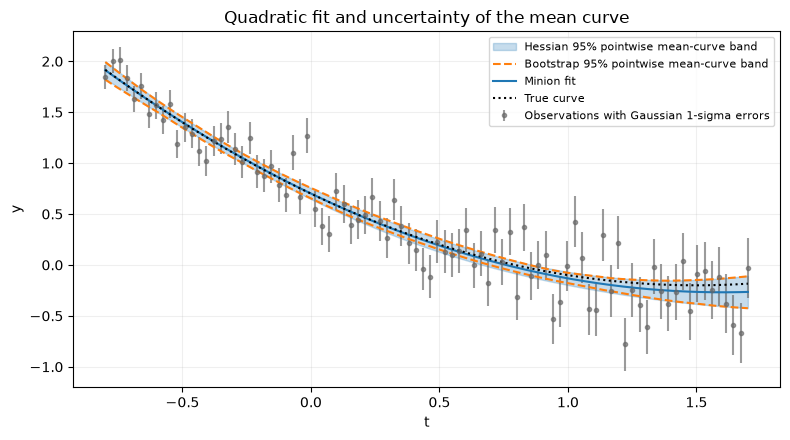

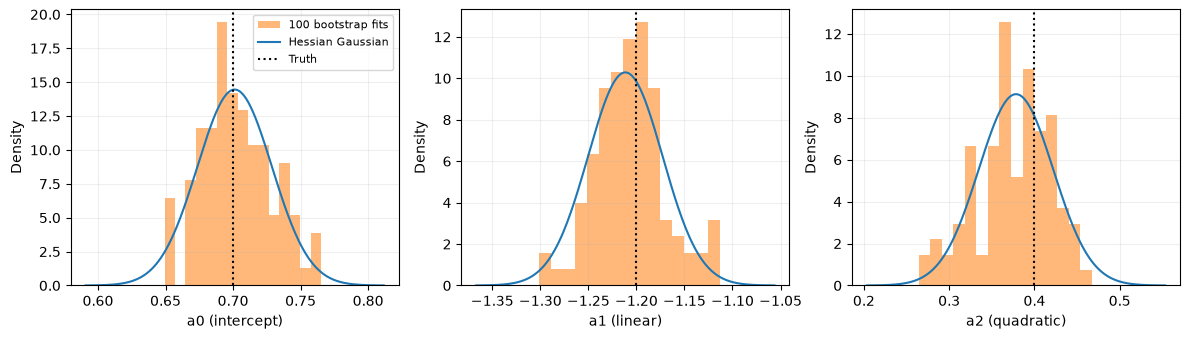

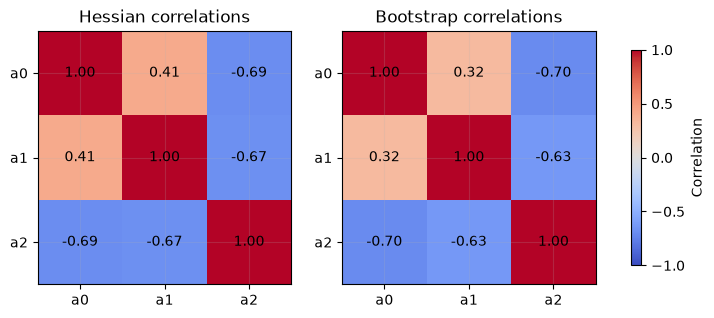

In [6]:
grid = np.linspace(t.min(), t.max(), 300)
grid_design = np.column_stack([np.ones_like(grid), grid, grid**2])
prediction = grid_design @ best_parameters
prediction_std = np.sqrt(np.einsum("ij,jk,ik->i", grid_design, hessian_covariance, grid_design))
bootstrap_curves = bootstrap_parameters @ grid_design.T
bootstrap_band = np.percentile(bootstrap_curves, [2.5, 97.5], axis=0)
z = NormalDist().inv_cdf(0.975)

fig, ax = plt.subplots()
ax.errorbar(t, observed, yerr=sigma, fmt=".", color="0.4", alpha=0.65,
            label="Observations with Gaussian 1-sigma errors")
ax.fill_between(grid, prediction - z*prediction_std, prediction + z*prediction_std,
                alpha=0.25, color="C0", label="Hessian 95% pointwise mean-curve band")
ax.plot(grid, bootstrap_band[0], "--", color="C1", label="Bootstrap 95% pointwise mean-curve band")
ax.plot(grid, bootstrap_band[1], "--", color="C1")
ax.plot(grid, prediction, color="C0", label="Minion fit")
ax.plot(grid, grid_design @ true_parameters, ":", color="black", label="True curve")
ax.set(xlabel="t", ylabel="y", title="Quadratic fit and uncertainty of the mean curve")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for j, ax in enumerate(axes):
    ax.hist(bootstrap_parameters[:, j], bins=15, density=True, alpha=0.55,
            color="C1", label="100 bootstrap fits")
    values = np.linspace(best_parameters[j] - 4*hessian_std[j],
                         best_parameters[j] + 4*hessian_std[j], 250)
    density = np.exp(-0.5*((values-best_parameters[j])/hessian_std[j])**2)
    density /= np.sqrt(2*np.pi)*hessian_std[j]
    ax.plot(values, density, color="C0", label="Hessian Gaussian")
    ax.axvline(true_parameters[j], color="black", linestyle=":", label="Truth")
    ax.set(xlabel=parameter_names[j], ylabel="Density")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, matrix, title in zip(axes, [hessian_result.correlation, bootstrap_correlation],
                            ["Hessian correlations", "Bootstrap correlations"]):
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set(xticks=range(3), yticks=range(3), xticklabels=["a0", "a1", "a2"],
           yticklabels=["a0", "a1", "a2"], title=title)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{matrix[i,j]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=list(axes), label="Correlation", shrink=0.8)
plt.show()


The two methods estimate the same uncertainty in this example: Gaussian errors
with known variances and a model linear in its coefficients give an exactly
quadratic chi-squared objective. Bootstrap differences are chiefly finite-replica
sampling fluctuations. The plotted bands describe uncertainty in the **mean
curve**, not prediction intervals for future noisy observations, and are pointwise
rather than simultaneous bands. Increase `n_replicas` for more stable bootstrap
uncertainties and percentiles.
